# IE4483 Sentiment Analysis: our own neural model (BiLSTM + attention)

Part 1 (`tfidf_baseline.ipynb`) used TF-IDF + logistic regression. It reaches about 89% accuracy but finds only about 30% of the negative reviews. This notebook builds **our own neural classifier**: a bidirectional LSTM with attention pooling, written and trained here from start to finish, with no pretrained language model. Two variants with the same architecture are compared:

| Variant | Embedding layer initialisation | Everything else |
|---|---|---|
| **A: BiLSTM-scratch** | random, learned only from `train.json` | identical |
| **B: BiLSTM-GloVe** | GloVe 100-d word vectors [Pennington et al., 2014], then fine-tuned | identical |

Contents: 0. How to run · 1. Data and preprocessing · 2. Model architecture (figure + dimensions) · 3. Loss and training strategy · 4. Hyper-parameter selection · 5. Reproducibility (3 seeds) · 6. Comparison with logistic regression · 7. Error analysis · 8. Test predictions

## 0. How to run
1. Open this notebook from the `IE4483 Project` folder and select the kernel **"Python (IE4483 sentiment_project)"** (the project's `.venv`: Python, PyTorch, scikit-learn, pandas, matplotlib).
2. GloVe vectors (`glove-wiki-gigaword-100`, 128 MB) are downloaded automatically to `~/glove/` the first time.
3. Run all cells. Every training run is cached in `sentiment_project/results/bilstm_runs.pkl`, so a second run takes about a minute. Set `RUN_ALL = True` in the next cell to retrain everything from scratch (about 25 minutes on an Apple M4 Pro CPU).

Training runs on the **CPU** on purpose. On this machine it was faster than the Apple GPU (MPS) for this small LSTM (about 19 s vs 33 s per epoch in a benchmark). CPU results are also bit-for-bit reproducible for a fixed seed; section 5 checks this.

In [1]:
import sys, time, pickle, json, gzip, urllib.request, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

sys.path.insert(0, 'sentiment_project/src')           # reuse the project's helpers
from common import RESULTS, SEED, SEEDS, set_seed     # SEED=42, SEEDS=[42, 43, 44]
from data_loader import load_train, load_test
from preprocessing import tokenize
from splits import holdout
from evaluate import metrics

RUN_ALL = False                                        # True = ignore the cache and retrain every run
DEVICE = torch.device('cpu')
CACHE = RESULTS / 'bilstm_runs.pkl'
GLOVE = Path.home() / 'glove' / 'glove-wiki-gigaword-100.gz'

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e6e5e0'
COL = {'scratch': ORANGE, 'glove': BLUE}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'font.size': 10})
pd.set_option('display.max_colwidth', 110)
print('torch', torch.__version__, '| device', DEVICE, '| threads', torch.get_num_threads())

torch 2.14.1 | device cpu | threads 8


## 1. Data and preprocessing

**Split:** the same grouped, stratified 80/20 hold-out fold as the TF-IDF model (`splits.holdout`), so the comparison is fair. Duplicate reviews never appear on both sides. `test.json` has no labels and is used only in section 8.

**Tokenisation** (`preprocessing.tokenize`, shared with the TF-IDF experiments):
- lowercase and HTML-unescape the text
- keep contractions whole (`don't`, `isn't`) and keep `!` and `?` as tokens, since they carry sentiment
- **no stop-word removal**, so negations such as *not*, *no* and *never* survive

Default TF-IDF instead drops one-letter words and splits `don't` into `don`.

In [2]:
df, test_df = load_train(), load_test()
X_text, y = df['reviews'].values, df['sentiments'].values
tr_idx, va_idx = holdout(df)
print(f'train part {len(tr_idx)} | validation {len(va_idx)} | test (unlabelled) {len(test_df)}')
print(f'positive rate: train part {y[tr_idx].mean():.3f}, validation {y[va_idx].mean():.3f}')

s = "I didn't like it AT ALL!! The zipper broke after 2 days... NOT worth $20?"
print('\nraw:   ', s)
print('tokens:', tokenize(s))

train part 5921 | validation 1480 | test (unlabelled) 1851
positive rate: train part 0.854, validation 0.854

raw:    I didn't like it AT ALL!! The zipper broke after 2 days... NOT worth $20?
tokens: ['i', "didn't", 'like', 'it', 'at', 'all', '!', '!', 'the', 'zipper', 'broke', 'after', '2', 'days', 'not', 'worth', '20', '?']


**Vocabulary and sequence length.** The vocabulary is built from the **training part only**. Words seen fewer than 2 times are mapped to `<unk>`: they are mostly typos, and the model can't learn anything reliable from one example. Index 0 is `<pad>`. Sequences are cut at **T_max = 256** tokens, which keeps about 99% of reviews whole. Batches are padded only to their longest review, and reviews of similar length are batched together, so very little time is spent on padding.

distinct tokens in training part: 12,809 -> vocabulary (min_freq=2): 6,893
validation tokens mapped to <unk>: 3.12%
review length (tokens): median 43, 95th pct 145, max 1076; truncated at 256: 1.11% of reviews


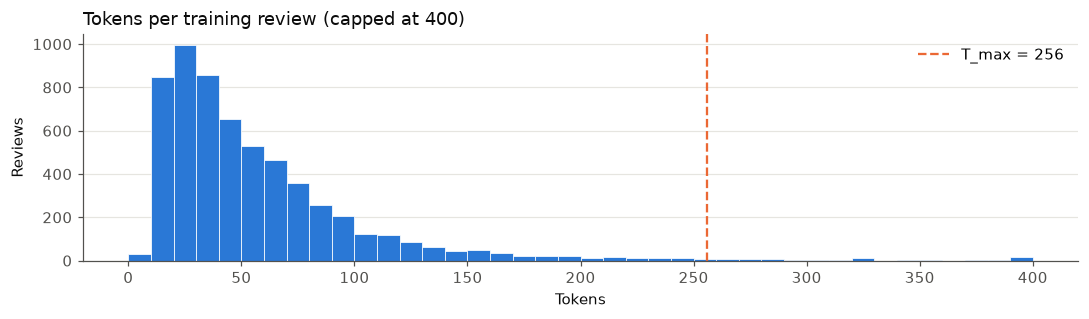

In [3]:
MAX_LEN, MIN_FREQ, BATCH = 256, 2, 64

def build_vocab(texts, min_freq=MIN_FREQ):
    c = collections.Counter(t for s in texts for t in tokenize(s))
    vocab = {'<pad>': 0, '<unk>': 1}
    for w, n in c.most_common():
        if n >= min_freq:
            vocab[w] = len(vocab)
    return vocab, c

def encode(texts, vocab):
    return [[vocab.get(t, 1) for t in tokenize(s)][:MAX_LEN] or [1] for s in texts]

vocab_tr, counts_tr = build_vocab(X_text[tr_idx])
lens = np.array([len(tokenize(s)) for s in X_text[tr_idx]])
ids_va = encode(X_text[va_idx], vocab_tr)
unk_rate = np.mean([t == 1 for r in ids_va for t in r])
print(f'distinct tokens in training part: {len(counts_tr):,} -> vocabulary (min_freq={MIN_FREQ}): {len(vocab_tr):,}')
print(f'validation tokens mapped to <unk>: {unk_rate:.2%}')
print(f'review length (tokens): median {np.median(lens):.0f}, 95th pct {np.percentile(lens, 95):.0f}, '
      f'max {lens.max()}; truncated at {MAX_LEN}: {np.mean(lens > MAX_LEN):.2%} of reviews')

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(np.clip(lens, 0, 400), bins=np.arange(0, 410, 10), color=BLUE, edgecolor='white', linewidth=0.5)
ax.axvline(MAX_LEN, color=ORANGE, linestyle='--', linewidth=1.5, label=f'T_max = {MAX_LEN}')
ax.set_title('Tokens per training review (capped at 400)', loc='left', color=INK)
ax.set_xlabel('Tokens'); ax.set_ylabel('Reviews'); ax.legend(frameon=False); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**GloVe initialisation (variant B).** Each vocabulary word gets its 100-d GloVe vector [Pennington et al., 2014] (6B-token Wikipedia + Gigaword corpus). GloVe splits contractions (`don't` → `do` + `n't`), so a whole contraction gets the mean of its two pieces. Words GloVe doesn't know get small random vectors with the same spread as the GloVe vectors, and `<pad>` is all zeros. The vectors are a **starting point only**: they are fine-tuned along with the rest of the network.

In [4]:
if not GLOVE.exists():
    GLOVE.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve('https://github.com/RaRe-Technologies/gensim-data/releases/download/'
                               'glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz', GLOVE)

def load_glove(needed):
    vecs = {}
    with gzip.open(GLOVE, 'rt', encoding='utf8') as f:
        next(f)                                         # header line: "400000 100"
        for line in f:
            w, rest = line.split(' ', 1)
            if w in needed:
                vecs[w] = np.asarray(rest.split(), dtype=np.float32)
    return vecs

def glove_pieces(w):
    if "'" not in w:
        return [w]
    if w.endswith("n't"):
        return [w[:-3], "n't"]
    a, b = w.split("'", 1)
    return [a, "'" + b]

all_vocab = build_vocab(X_text)[0]                      # superset, so one GloVe pass serves every split
needed = {p for w in all_vocab for p in glove_pieces(w)}
t0 = time.time(); GLOVE_VECS = load_glove(needed)
G_STD = float(np.std(np.stack(list(GLOVE_VECS.values()))))
print(f'loaded {len(GLOVE_VECS):,} GloVe vectors in {time.time() - t0:.0f}s (std {G_STD:.3f})')

def glove_matrix(vocab, seed):
    rng = np.random.default_rng(seed)
    E = rng.normal(0, G_STD, (len(vocab), 100)).astype(np.float32)
    E[0] = 0.0
    hit = 0
    for w, i in vocab.items():
        parts = [GLOVE_VECS[p] for p in glove_pieces(w) if p in GLOVE_VECS]
        if i > 1 and parts:
            E[i] = np.mean(parts, 0); hit += 1
    return torch.from_numpy(E), hit / (len(vocab) - 2)

_, cov = glove_matrix(vocab_tr, SEED)
tok_cov = np.mean([any(p in GLOVE_VECS for p in glove_pieces(t)) for s in X_text[tr_idx][:2000] for t in tokenize(s)])
print(f'GloVe covers {cov:.1%} of the vocabulary types and {tok_cov:.1%} of running tokens')

loaded 7,256 GloVe vectors in 1s (std 0.518)
GloVe covers 95.8% of the vocabulary types and 98.3% of running tokens


## 2. Model architecture

```
review text ──tokenize──▶ token ids x ∈ ℕ^(B×T)          (B = batch size, T ≤ 256 = longest review in batch)
  │
  ▼  Embedding(V, d)                 A: random d=128   B: GloVe d=100 (fine-tuned)        → (B, T, d)
  ▼  Dropout(p)
  ▼  BiLSTM(d → H per direction)     reads the review left→right and right→left           → (B, T, 2H)
  ├─▶ additive attention pooling     α_t = softmax_t( vᵀ tanh(W h_t) ),  c = Σ α_t h_t     → (B, 2H)
  └─▶ masked max-pooling             m = max_t h_t  (padding positions excluded)           → (B, 2H)
  ▼  concat [c ; m]                                                                         → (B, 4H)
  ▼  Dropout(p)  →  Linear(4H, 2)                                                           → logits (B, 2)
  ▼  softmax                                                                                → p(negative), p(positive)
```

**Why this design:**
- **BiLSTM:** reads the review in order, so it can model negation and contrast ("*not* comfortable", "looks nice *but* broke"). Bag-of-words TF-IDF can't see word order.
- **Attention pooling:** learns *which* words matter, so a review's sentiment can come from one sentence in a long review. The weights α can also be inspected (section 7).
- **Max-pooling:** keeps the strongest signal for each feature, which complements attention's weighted average.
- **Dropout:** regularises a model with about 1–2 M parameters trained on only about 6 k reviews.

In [5]:
class BiLSTMAttn(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, dropout, pretrained=None, freeze=False):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        if pretrained is not None:
            self.emb.weight.data.copy_(pretrained)
            self.emb.weight.requires_grad = not freeze
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.att_W = nn.Linear(2 * hidden, 2 * hidden)
        self.att_v = nn.Linear(2 * hidden, 1, bias=False)
        self.head = nn.Linear(4 * hidden, 2)

    def forward(self, x, lens, return_attn=False):
        e = self.drop(self.emb(x))                                               # (B, T, d)
        packed = pack_padded_sequence(e, lens, batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True, total_length=x.size(1))  # (B, T, 2H)
        mask = torch.arange(x.size(1))[None, :] < lens[:, None]                  # (B, T) True = real token
        scores = self.att_v(torch.tanh(self.att_W(h))).squeeze(-1).masked_fill(~mask, -1e9)
        alpha = torch.softmax(scores, 1)                                         # (B, T)
        ctx = (alpha.unsqueeze(-1) * h).sum(1)                                   # (B, 2H)
        mx = h.masked_fill(~mask.unsqueeze(-1), -1e9).max(1).values              # (B, 2H)
        logits = self.head(self.drop(torch.cat([ctx, mx], 1)))                   # (B, 2)
        return (logits, alpha) if return_attn else logits

### Input/output dimensions and parameter counts

In [6]:
def layer_table(model, x, lens):
    rows, hooks = [], []
    def hook(name):
        def f(m, i, o):
            o = o[0] if isinstance(o, tuple) else o
            shape = tuple(pad_packed_sequence(o, batch_first=True)[0].shape) if hasattr(o, 'batch_sizes') else tuple(o.shape)
            rows.append({'layer': name, 'module': m.__class__.__name__, 'output shape': str(shape),
                         'parameters': sum(p.numel() for p in m.parameters())})
        return f
    for name, m in model.named_children():
        hooks.append(m.register_forward_hook(hook(name)))
    model.eval()
    with torch.no_grad():
        model(x, lens)
    for h in hooks:
        h.remove()
    t = pd.DataFrame(rows).drop_duplicates('layer')
    total = sum(p.numel() for p in model.parameters())
    return pd.concat([t, pd.DataFrame([{'layer': 'TOTAL', 'module': '', 'output shape': '', 'parameters': total}])],
                     ignore_index=True)

xb = torch.randint(2, 100, (64, 120)); lb = torch.full((64,), 120)
print('Example batch: B=64 reviews, T=120 tokens, H=128, V =', len(vocab_tr))
print('\nVariant A (scratch, d=128):')
display(layer_table(BiLSTMAttn(len(vocab_tr), 128, 128, 0.4), xb, lb))
print('Variant B (GloVe, d=100):')
display(layer_table(BiLSTMAttn(len(vocab_tr), 100, 128, 0.4), xb, lb))

Example batch: B=64 reviews, T=120 tokens, H=128, V = 6893

Variant A (scratch, d=128):


,layer,module,output shape,parameters
0,emb,Embedding,"(64, 120, 128)",882304
1,drop,Dropout,"(64, 120, 128)",0
2,lstm,LSTM,"(64, 120, 256)",264192
3,att_W,Linear,"(64, 120, 256)",65792
4,att_v,Linear,"(64, 120, 1)",256
5,head,Linear,"(64, 2)",1026
6,TOTAL,,,1213570


Variant B (GloVe, d=100):


,layer,module,output shape,parameters
0,emb,Embedding,"(64, 120, 100)",689300
1,drop,Dropout,"(64, 120, 100)",0
2,lstm,LSTM,"(64, 120, 256)",235520
3,att_W,Linear,"(64, 120, 256)",65792
4,att_v,Linear,"(64, 120, 1)",256
5,head,Linear,"(64, 2)",1026
6,TOTAL,,,991894


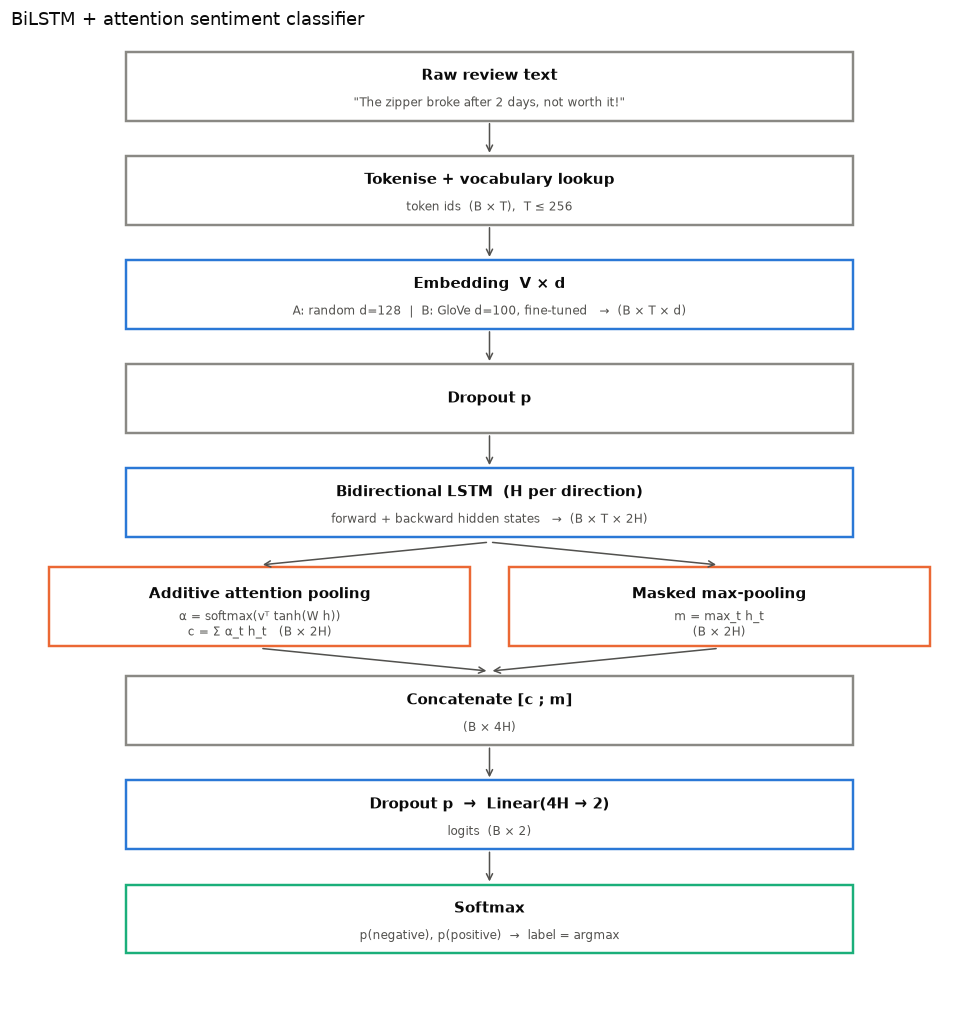

In [7]:
# Architecture figure (for the report)
def arch_figure():
    steps = [('Raw review text', '"The zipper broke after 2 days, not worth it!"', GRAY),
             ('Tokenise + vocabulary lookup', 'token ids  (B × T),  T ≤ 256', GRAY),
             ('Embedding  V × d', 'A: random d=128  |  B: GloVe d=100, fine-tuned   →  (B × T × d)', BLUE),
             ('Dropout p', '', GRAY),
             ('Bidirectional LSTM  (H per direction)', 'forward + backward hidden states   →  (B × T × 2H)', BLUE),
             (None, None, None),
             ('Concatenate [c ; m]', '(B × 4H)', GRAY),
             ('Dropout p  →  Linear(4H → 2)', 'logits  (B × 2)', BLUE),
             ('Softmax', 'p(negative), p(positive)  →  label = argmax', AQUA)]
    fig, ax = plt.subplots(figsize=(9, 9.5)); ax.set_axis_off(); ax.set_xlim(0, 10); ax.set_ylim(0, len(steps) + 0.5)
    for k, (title, sub, col) in enumerate(steps):
        yc = len(steps) - k
        if title is None:
            for xc, t, s in [(2.6, 'Additive attention pooling', 'α = softmax(vᵀ tanh(W h))\nc = Σ α_t h_t   (B × 2H)'),
                             (7.4, 'Masked max-pooling', 'm = max_t h_t\n(B × 2H)')]:
                ax.add_patch(plt.Rectangle((xc - 2.2, yc - 0.38), 4.4, 0.76, facecolor='white', edgecolor=ORANGE, linewidth=1.6))
                ax.text(xc, yc + 0.12, t, ha='center', va='center', fontsize=10, weight='bold', color=INK)
                ax.text(xc, yc - 0.17, s, ha='center', va='center', fontsize=8, color=MUTED)
                ax.annotate('', (xc, yc + 0.4), (5, yc + 0.62), arrowprops=dict(arrowstyle='->', color=MUTED))
                ax.annotate('', (5, yc - 0.62), (xc, yc - 0.4), arrowprops=dict(arrowstyle='->', color=MUTED))
            continue
        ax.add_patch(plt.Rectangle((1.2, yc - 0.33), 7.6, 0.66, facecolor='white', edgecolor=col, linewidth=1.6))
        ax.text(5, yc + (0.1 if sub else 0), title, ha='center', va='center', fontsize=10, weight='bold', color=INK)
        if sub:
            ax.text(5, yc - 0.16, sub, ha='center', va='center', fontsize=8, color=MUTED)
        nxt = steps[k + 1][0] if k + 1 < len(steps) else 'end'
        if k + 1 < len(steps) and nxt is not None and title != 'Bidirectional LSTM  (H per direction)':
            ax.annotate('', (5, yc - 0.67), (5, yc - 0.33), arrowprops=dict(arrowstyle='->', color=MUTED))
    ax.set_title('BiLSTM + attention sentiment classifier', loc='left', color=INK, fontsize=12)
    plt.tight_layout()
    return fig

fig = arch_figure(); fig.savefig('sentiment_project/figures/bilstm_architecture.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. Loss function and training strategy

| Item | Choice | Reason |
|---|---|---|
| Output | 2 logits → softmax | standard for 2-class classification; `argmax` = predicted label |
| **Loss** | **class-weighted cross-entropy**, w_c = N / (2·N_c) → w_neg ≈ 3.42, w_pos ≈ 0.59 | only 14.6% of reviews are negative. Without weights the model (like the LR) mostly predicts "positive". Weighting makes each class count equally |
| Optimiser | Adam, learning rate from the sweep (section 4) | adapts the step size per parameter; standard for LSTMs |
| Gradient clipping | max L2 norm 1.0 | prevents exploding gradients in recurrent networks |
| Batch size | 64, length-bucketed | small enough for regularising noise, large enough for speed; bucketing reduces padding |
| Epochs | up to 15, **early stopping** with patience 3 on validation macro-F1, best checkpoint restored | stops before overfitting; macro-F1 rather than accuracy, because accuracy rewards ignoring the minority class |
| Final model | refit on **all** of `train.json` for the median best epoch of the 3 seeds; test probabilities averaged over the 3 seeds | uses every labelled review; averaging seeds reduces variance |
| Reproducibility | fixed seeds (Python, NumPy, PyTorch, shuffling generator); CPU; results reported as mean ± std over seeds 42/43/44 | see section 5 |

**Limitation:** the hold-out fold is used both for early stopping and for picking hyper-parameters, so its scores are slightly optimistic. The tuned TF-IDF model was also tuned with cross-validation on the same data, so the comparison stays fair. The real test is `test.json`, which is graded by the course.

In [8]:
MAX_EPOCHS, PATIENCE = 15, 3
EMB_DIM = {'scratch': 128, 'glove': 100}

def batches(ids, gen, shuffle=True):
    n = len(ids)
    order = torch.randperm(n, generator=gen).tolist() if shuffle else list(range(n))
    chunk = BATCH * 50                                     # sort by length inside chunks -> little padding
    out = []
    for i in range(0, n, chunk):
        c = sorted(order[i:i + chunk], key=lambda j: len(ids[j]))
        out += [c[k:k + BATCH] for k in range(0, len(c), BATCH)]
    if shuffle:
        out = [out[i] for i in torch.randperm(len(out), generator=gen).tolist()]
    return out

def collate(ids, idx):
    L = torch.tensor([len(ids[j]) for j in idx])
    x = torch.zeros(len(idx), int(L.max()), dtype=torch.long)
    for r, j in enumerate(idx):
        x[r, :len(ids[j])] = torch.tensor(ids[j])
    return x, L

def predict_proba(model, ids):
    model.eval(); p = np.zeros(len(ids))
    with torch.no_grad():
        for idx in batches(ids, None, shuffle=False):
            x, L = collate(ids, idx)
            p[idx] = torch.softmax(model(x, L), 1)[:, 1].numpy()
    return p

def train_model(variant, cfg, tr_text, tr_y, va_text=None, va_y=None, seed=SEED, epochs=MAX_EPOCHS):
    """With validation data: early stopping on val macro-F1. Without: train exactly `epochs` epochs."""
    set_seed(seed)
    vocab, _ = build_vocab(tr_text)
    pre = glove_matrix(vocab, seed)[0] if variant == 'glove' else None
    model = BiLSTMAttn(len(vocab), EMB_DIM[variant], cfg['hidden'], cfg['dropout'], pre, cfg.get('freeze', False))
    w = torch.tensor(len(tr_y) / (2 * np.bincount(tr_y, minlength=2)), dtype=torch.float32)
    loss_fn = nn.CrossEntropyLoss(weight=w if cfg.get('class_weight', True) else None)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=cfg['lr'])
    ids_tr, yt = encode(tr_text, vocab), torch.tensor(tr_y)
    ids_va = encode(va_text, vocab) if va_text is not None else None
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_ep, bad, hist, t0 = -1, None, epochs, 0, [], time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot = 0.0
        for idx in batches(ids_tr, gen):
            x, L = collate(ids_tr, idx)
            opt.zero_grad()
            loss = loss_fn(model(x, L), yt[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); tot += loss.item() * len(idx)
        rec = {'epoch': ep, 'train_loss': tot / len(ids_tr)}
        if ids_va is not None:
            p = predict_proba(model, ids_va)
            m = metrics(va_y, (p >= 0.5).astype(int), p)
            rec.update(val_loss=float(nn.functional.cross_entropy(torch.log(torch.tensor(np.c_[1 - p, p]).clamp_min(1e-7)),
                                                                   torch.tensor(va_y), weight=w.double()).item()),
                       val_macro_f1=m['macro_f1'], val_acc=m['accuracy'])
            if m['macro_f1'] > best:
                best, best_ep, bad = m['macro_f1'], ep, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
        hist.append(rec)
        if ids_va is not None and bad >= PATIENCE:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, vocab, best_ep, hist, time.time() - t0

# ---- cache: every (variant, config, seed) run is stored, so the notebook re-runs quickly
RUNS = pickle.load(open(CACHE, 'rb')) if CACHE.exists() and not RUN_ALL else {}

def run(variant, cfg, seed=SEED):
    """Train on the train part, evaluate on the hold-out fold (cached)."""
    key = (variant, json.dumps(cfg, sort_keys=True), seed)
    if key not in RUNS:
        model, vocab, best_ep, hist, secs = train_model(variant, cfg, X_text[tr_idx], y[tr_idx],
                                                        X_text[va_idx], y[va_idx], seed=seed)
        p = predict_proba(model, encode(X_text[va_idx], vocab))
        RUNS[key] = {'variant': variant, **cfg, 'seed': seed, 'best_epoch': best_ep, 'train_seconds': round(secs, 1),
                     'n_params': sum(q.numel() for q in model.parameters()), 'p_val': p, 'history': hist,
                     **{k: v for k, v in metrics(y[va_idx], (p >= 0.5).astype(int), p).items()}}
        pickle.dump(RUNS, open(CACHE, 'wb'))
        r = RUNS[key]
        print(f"  trained {variant:7s} {cfg} seed {seed}: macro-F1 {r['macro_f1']:.4f} acc {r['accuracy']:.4f} "
              f"(best epoch {best_ep}, {secs:.0f}s)")
    return RUNS[key]

## 4. Hyper-parameter selection

**Method:** a full grid (4 × 3 × 3 × 2 = 72 runs per variant) would take hours, so parameters are tuned **one at a time** in order of expected impact. Each step keeps the best value found so far. Every run uses seed 42 and the same hold-out fold, and is **scored on macro-F1**.

| Step | Parameter | Values tried | Why this range |
|---|---|---|---|
| start | | lr 1e-3, H 128, dropout 0.4, weighted loss | Adam's usual default; mid-size LSTM; moderate dropout |
| 1 | learning rate | 5e-4, 1e-3, 2e-3, 3e-3 | the most sensitive setting: too small trains slowly or stops early, too large is unstable |
| 2 | hidden size H | 64, 128, 256 | model capacity against overfitting on about 6 k reviews |
| 3 | dropout p | 0.2, 0.4, 0.6 | regularisation strength |
| 4 | class-weighted loss | on, off | does weighting really help the minority class? |
| 5 (GloVe only) | freeze embeddings | fine-tune, frozen | is adapting GloVe to product reviews worth it? |

Fixed by design rather than swept: embedding size (128 scratch / 100 GloVe), batch size 64, T_max 256, min_freq 2, 1 LSTM layer. A 2nd layer adds parameters that 6 k reviews can't support.

In [9]:
SWEEP = {'lr': [5e-4, 1e-3, 2e-3, 3e-3], 'hidden': [64, 128, 256], 'dropout': [0.2, 0.4, 0.6], 'class_weight': [True, False]}
BASE = {'lr': 1e-3, 'hidden': 128, 'dropout': 0.4, 'class_weight': True}

sweep_rows, BEST = [], {}
for variant in ['scratch', 'glove']:
    cfg = dict(BASE)
    steps = list(SWEEP.items()) + ([('freeze', [False, True])] if variant == 'glove' else [])
    for step, (param, values) in enumerate(steps, 1):
        res = []
        for v in values:
            c = {**cfg, param: v}
            if param != 'freeze':
                c.pop('freeze', None)
            r = run(variant, c)
            res.append((r['macro_f1'], v))
            sweep_rows.append({'variant': variant, 'step': step, 'param': param, 'value': v,
                               **{k: r[k] for k in ['macro_f1', 'accuracy', 'recall_neg', 'roc_auc', 'best_epoch', 'train_seconds']}})
        cfg[param] = max(res, key=lambda t: t[0])[1]
    if not cfg.get('freeze'):
        cfg.pop('freeze', None)
    BEST[variant] = cfg

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RESULTS / 'bilstm_sweep.csv', index=False)
for v in BEST:
    print(f'best {v:7s}: {BEST[v]}')

  trained scratch {'lr': 0.0005, 'hidden': 128, 'dropout': 0.4, 'class_weight': True} seed 42: macro-F1 0.7829 acc 0.8791 (best epoch 9, 69s)


  trained scratch {'lr': 0.001, 'hidden': 128, 'dropout': 0.4, 'class_weight': True} seed 42: macro-F1 0.8144 acc 0.8993 (best epoch 9, 66s)


  trained scratch {'lr': 0.002, 'hidden': 128, 'dropout': 0.4, 'class_weight': True} seed 42: macro-F1 0.8473 acc 0.9264 (best epoch 9, 66s)


  trained scratch {'lr': 0.003, 'hidden': 128, 'dropout': 0.4, 'class_weight': True} seed 42: macro-F1 0.8293 acc 0.9115 (best epoch 6, 49s)


  trained scratch {'lr': 0.002, 'hidden': 64, 'dropout': 0.4, 'class_weight': True} seed 42: macro-F1 0.8504 acc 0.9250 (best epoch 9, 41s)


  trained scratch {'lr': 0.002, 'hidden': 256, 'dropout': 0.4, 'class_weight': True} seed 42: macro-F1 0.8436 acc 0.9257 (best epoch 9, 128s)


... (10 outputs left out)

  trained glove   {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': True} seed 42: macro-F1 0.8564 acc 0.9257 (best epoch 7, 108s)


  trained glove   {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False} seed 42: macro-F1 0.8653 acc 0.9365 (best epoch 10, 139s)


  trained glove   {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False, 'freeze': False} seed 42: macro-F1 0.8653 acc 0.9365 (best epoch 10, 138s)


  trained glove   {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False, 'freeze': True} seed 42: macro-F1 0.7941 acc 0.9101 (best epoch 6, 94s)
best scratch: {'lr': 0.002, 'hidden': 64, 'dropout': 0.4, 'class_weight': True}
best glove  : {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False}


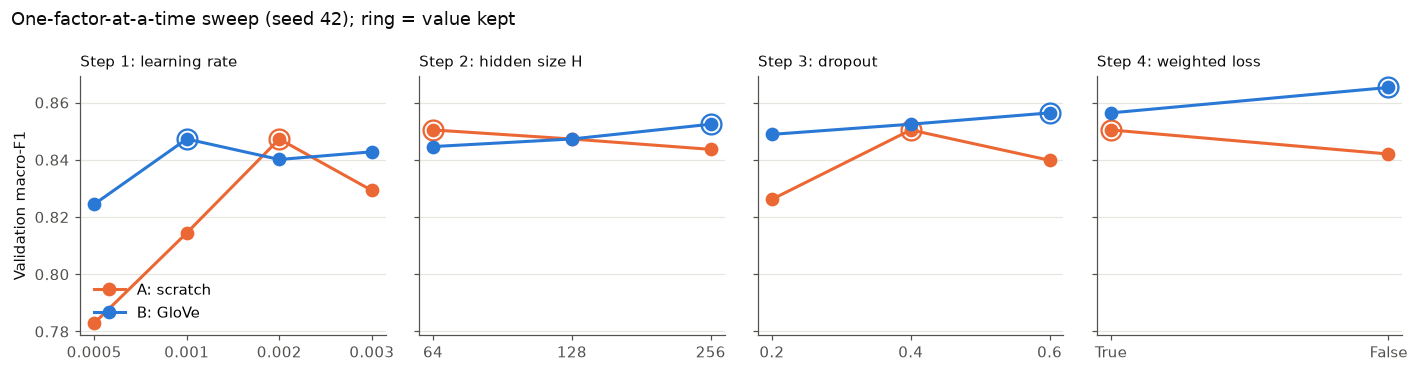

,variant,step,param,value,macro_f1,accuracy,recall_neg,roc_auc,best_epoch,train_seconds
0,scratch,1,lr,0.0005,0.7829,0.8791,0.7315,0.9163,9,68.6
1,scratch,1,lr,0.001,0.8144,0.8993,0.7639,0.9358,9,66.3
2,scratch,1,lr,0.002,0.8473,0.9264,0.7083,0.9379,9,65.8
3,scratch,1,lr,0.003,0.8293,0.9115,0.7454,0.9379,6,49.3
4,scratch,2,hidden,64,0.8504,0.9250,0.7500,0.9356,9,41.2
5,scratch,2,hidden,128,0.8473,0.9264,0.7083,0.9379,9,65.8
6,scratch,2,hidden,256,0.8436,0.9257,0.6898,0.9366,9,128.1
7,scratch,3,dropout,0.2,0.8262,0.9128,0.7083,0.9367,6,31.5
8,scratch,3,dropout,0.4,0.8504,0.9250,0.7500,0.9356,9,41.2
9,scratch,3,dropout,0.6,0.8398,0.9189,0.7407,0.9321,10,45.5


In [10]:
params = ['lr', 'hidden', 'dropout', 'class_weight']
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, prm in zip(axes, params):
    for variant in ['scratch', 'glove']:
        s = sweep[(sweep.variant == variant) & (sweep.param == prm)]
        xs = [str(v) for v in s.value]
        ax.plot(xs, s.macro_f1, 'o-', color=COL[variant], linewidth=2, markersize=8,
                label='A: scratch' if variant == 'scratch' else 'B: GloVe')
        b = s.loc[s.macro_f1.idxmax()]
        ax.plot(str(b.value), b.macro_f1, 'o', markersize=13, markerfacecolor='none', markeredgecolor=COL[variant], markeredgewidth=1.5)
    ax.set_title({'lr': 'Step 1: learning rate', 'hidden': 'Step 2: hidden size H', 'dropout': 'Step 3: dropout',
                  'class_weight': 'Step 4: weighted loss'}[prm], loc='left', color=INK, fontsize=10)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Validation macro-F1'); axes[0].legend(frameon=False, loc='lower left')
fig.suptitle('One-factor-at-a-time sweep (seed 42); ring = value kept', x=0.01, ha='left', color=INK)
plt.tight_layout(); plt.show()

show = sweep.copy(); show['value'] = show['value'].astype(str)
show.round(4)

<!-- SWEEP_DISCUSSION -->

## 5. Reproducibility: 3 seeds per variant

The best configuration of each variant is retrained with seeds **42, 43 and 44**. The seed controls weight initialisation, dropout masks, batch order and the random vectors for words GloVe doesn't know. Results are reported as **mean ± standard deviation**. Seed 42 was already trained in the sweep. Retraining it from scratch and getting **identical** numbers shows that a fixed seed reproduces a run exactly.

In [11]:
seed_rows = []
for variant, cfg in BEST.items():
    for seed in SEEDS:
        r = run(variant, cfg, seed)
        seed_rows.append({'variant': variant, 'seed': seed, **{k: r[k] for k in
                          ['accuracy', 'macro_f1', 'recall_neg', 'f1_neg', 'roc_auc', 'best_epoch', 'train_seconds', 'n_params']}})
seeds_df = pd.DataFrame(seed_rows)
summary = seeds_df.groupby('variant')[['accuracy', 'macro_f1', 'recall_neg', 'roc_auc']].agg(['mean', 'std']).round(4)
display(seeds_df.round(4)); display(summary)

# determinism check: retrain seed 42 of the best scratch config without the cache
v0 = min(BEST, key=lambda v: RUNS[(v, json.dumps(BEST[v], sort_keys=True), SEED)]['train_seconds'])
m_re, voc_re, *_ = train_model(v0, BEST[v0], X_text[tr_idx], y[tr_idx], X_text[va_idx], y[va_idx], seed=SEED)
p_re = predict_proba(m_re, encode(X_text[va_idx], voc_re))
p_cached = RUNS[(v0, json.dumps(BEST[v0], sort_keys=True), SEED)]['p_val']
print(f'Determinism check ({v0}, seed 42 retrained): max |Δ p| = {np.abs(p_re - p_cached).max():.2e}, '
      f'identical predictions: {np.array_equal(p_re >= 0.5, p_cached >= 0.5)}')

  trained scratch {'lr': 0.002, 'hidden': 64, 'dropout': 0.4, 'class_weight': True} seed 43: macro-F1 0.8316 acc 0.9155 (best epoch 9, 42s)


  trained scratch {'lr': 0.002, 'hidden': 64, 'dropout': 0.4, 'class_weight': True} seed 44: macro-F1 0.8404 acc 0.9189 (best epoch 13, 52s)


  trained glove   {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False} seed 43: macro-F1 0.8454 acc 0.9203 (best epoch 5, 86s)


  trained glove   {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False} seed 44: macro-F1 0.8569 acc 0.9284 (best epoch 5, 85s)


,variant,seed,accuracy,macro_f1,recall_neg,f1_neg,roc_auc,best_epoch,train_seconds,n_params
0,scratch,42,0.9250,0.8504,0.7500,0.7448,0.9356,9,41.2,998786
1,scratch,43,0.9155,0.8316,0.7176,0.7126,0.9343,9,41.8,998786
2,scratch,44,0.9189,0.8404,0.7454,0.7285,0.9322,13,52.0,998786
3,glove,42,0.9365,0.8653,0.7176,0.7673,0.9483,10,139.1,1687702
4,glove,43,0.9203,0.8454,0.7685,0.7378,0.9379,5,86.2,1687702
5,glove,44,0.9284,0.8569,0.7593,0.7558,0.9409,5,85.2,1687702


accuracy         macro_f1         recall_neg         roc_auc        
            mean     std     mean     std       mean     std    mean     std
variant                                                                     
glove     0.9284  0.0081   0.8559  0.0100     0.7485  0.0271  0.9423  0.0053
scratch   0.9198  0.0048   0.8408  0.0094     0.7377  0.0175  0.9340  0.0017

Determinism check (scratch, seed 42 retrained): max |Δ p| = 0.00e+00, identical predictions: True


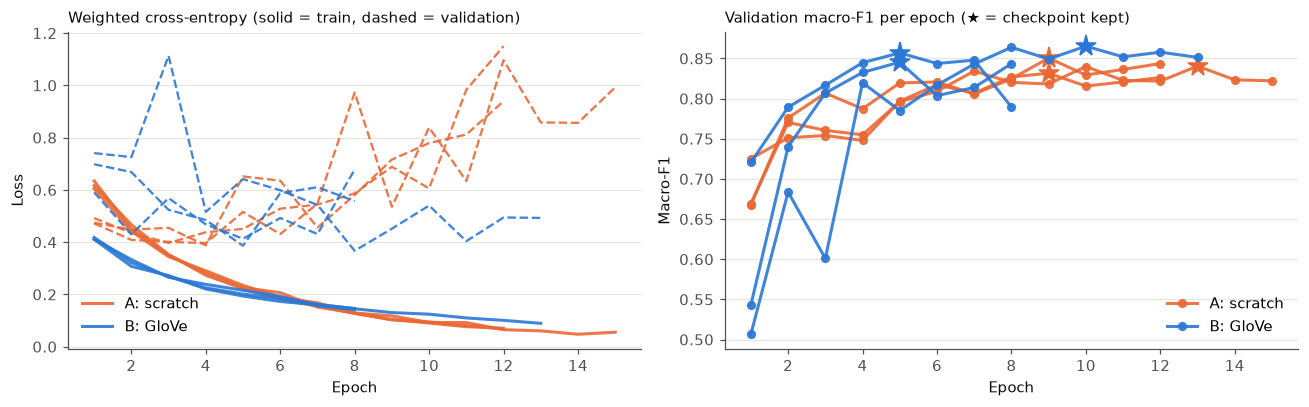

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for variant in BEST:
    for seed in SEEDS:
        h = pd.DataFrame(RUNS[(variant, json.dumps(BEST[variant], sort_keys=True), seed)]['history'])
        lab = ('A: scratch' if variant == 'scratch' else 'B: GloVe') if seed == SEED else None
        axes[0].plot(h.epoch, h.train_loss, '-', color=COL[variant], linewidth=2, alpha=0.9, label=lab)
        axes[0].plot(h.epoch, h.val_loss, '--', color=COL[variant], linewidth=1.5, alpha=0.9)
        axes[1].plot(h.epoch, h.val_macro_f1, 'o-', color=COL[variant], linewidth=2, markersize=5, alpha=0.9, label=lab)
        b = h.val_macro_f1.idxmax()
        axes[1].plot(h.epoch[b], h.val_macro_f1[b], '*', color=COL[variant], markersize=14)
axes[0].set_title('Weighted cross-entropy (solid = train, dashed = validation)', loc='left', color=INK, fontsize=10)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(frameon=False)
axes[1].set_title('Validation macro-F1 per epoch (★ = checkpoint kept)', loc='left', color=INK, fontsize=10)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Macro-F1'); axes[1].legend(frameon=False, loc='lower right')
for ax in axes: ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**Reading the curves:** training loss keeps falling while validation loss reaches its minimum after a few epochs and then rises. That is classic overfitting, and early stopping on validation macro-F1 keeps the checkpoint from before it sets in (★).

## 6. Comparison with the TF-IDF + logistic regression models

All models are scored on the **same** hold-out fold. The two TF-IDF models are retrained here:
- **LR (default):** Part 1's model, default `TfidfVectorizer()` + `LogisticRegression()`
- **LR (tuned):** the project's best TF-IDF config from 5-fold CV (`results/best_tfidf_config.json`: word 1–2-grams + character 2–5-grams, C=4, balanced class weights)

BiLSTM rows show the mean ± std of 3 seeds, plus the **3-seed ensemble** (averaged probabilities) that is used for the test predictions.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from train_tfidf import featurise, make_clf

t0 = time.time()
vec = TfidfVectorizer().fit(X_text[tr_idx])
lr0 = LogisticRegression(max_iter=1000, random_state=SEED).fit(vec.transform(X_text[tr_idx]), y[tr_idx])
p_lr0 = lr0.predict_proba(vec.transform(X_text[va_idx]))[:, 1]; s_lr0 = time.time() - t0

bc = json.loads((RESULTS / 'best_tfidf_config.json').read_text())
t0 = time.time()
_, Xtr_t, (Xva_t,) = featurise({'ngram': tuple(bc['ngram']), 'char': bc['char_wb_2_5'], 'min_df': bc['min_df']},
                               X_text[tr_idx], X_text[va_idx])
lr1 = make_clf('lr', {'C': bc['C'], 'class_weight': bc['class_weight']}).fit(Xtr_t, y[tr_idx])
p_lr1 = lr1.predict_proba(Xva_t)[:, 1]; s_lr1 = time.time() - t0

def row(name, p, params, secs, std=None):
    m = metrics(y[va_idx], (p >= 0.5).astype(int), p)
    r = {'model': name, 'accuracy': m['accuracy'], 'macro_f1': m['macro_f1'], 'recall_neg': m['recall_neg'],
         'precision_neg': m['precision_neg'], 'roc_auc': m['roc_auc'], 'parameters': params, 'train_s': round(secs, 1)}
    if std is not None:
        r.update({k: f"{seeds_df[seeds_df.variant == std][k].mean():.4f} ± {seeds_df[seeds_df.variant == std][k].std():.4f}"
                  for k in ['accuracy', 'macro_f1', 'recall_neg', 'roc_auc']})
    return r

P = {'LR (default)': p_lr0, 'LR (tuned)': p_lr1}
rows = [row('TF-IDF + LR (default, Part 1)', p_lr0, lr0.coef_.size + 1, s_lr0),
        row('TF-IDF + LR (tuned)', p_lr1, lr1.coef_.size + 1, s_lr1)]
for variant, name in [('scratch', 'BiLSTM-attn A: scratch'), ('glove', 'BiLSTM-attn B: GloVe')]:
    rs = [RUNS[(variant, json.dumps(BEST[variant], sort_keys=True), s)] for s in SEEDS]
    rows.append(row(name + ' (3 seeds, mean ± std)', rs[0]['p_val'], rs[0]['n_params'],
                    np.mean([r['train_seconds'] for r in rs]), std=variant))
    P[f'{variant} ensemble'] = np.mean([r['p_val'] for r in rs], 0)
    rows.append(row(name + ' (3-seed ensemble)', P[f'{variant} ensemble'], rs[0]['n_params'],
                    sum(r['train_seconds'] for r in rs)))
comp = pd.DataFrame(rows)
comp.to_csv(RESULTS / 'model_comparison.csv', index=False)
comp.round(4)

,model,accuracy,macro_f1,recall_neg,precision_neg,roc_auc,parameters,train_s
0,"TF-IDF + LR (default, Part 1)",0.892568,0.687407,0.282407,0.9385,0.936258,12522,0.2
1,TF-IDF + LR (tuned),0.916892,0.838537,0.75463,0.6996,0.949166,89997,2.1
2,"BiLSTM-attn A: scratch (3 seeds, mean ± std)",0.9198 ± 0.0048,0.8408 ± 0.0094,0.7377 ± 0.0175,0.7397,0.9340 ± 0.0017,998786,45.0
3,BiLSTM-attn A: scratch (3-seed ensemble),0.923649,0.845376,0.726852,0.7441,0.945723,998786,135.0
4,"BiLSTM-attn B: GloVe (3 seeds, mean ± std)",0.9284 ± 0.0081,0.8559 ± 0.0100,0.7485 ± 0.0271,0.8245,0.9423 ± 0.0053,1687702,103.5
5,BiLSTM-attn B: GloVe (3-seed ensemble),0.934459,0.866226,0.75463,0.7874,0.9444,1687702,310.5


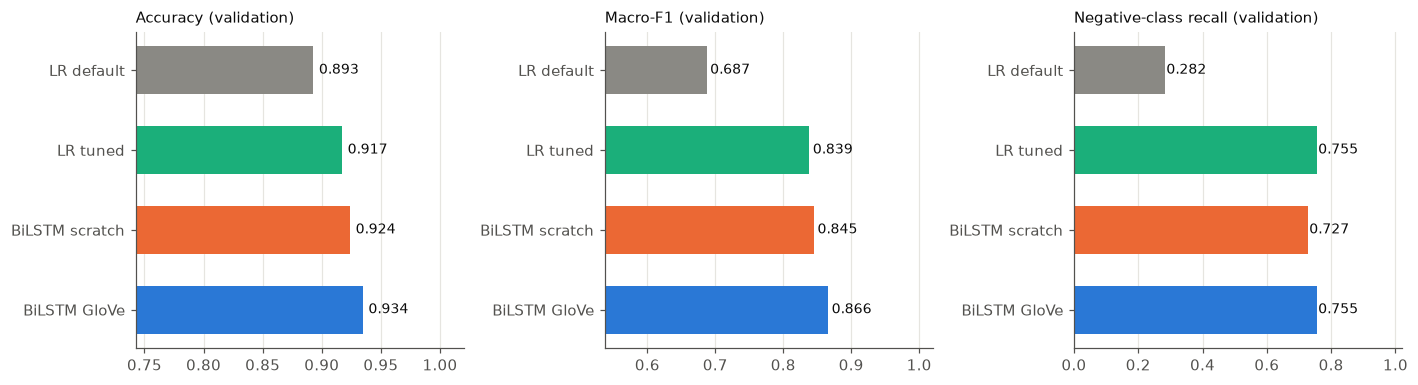

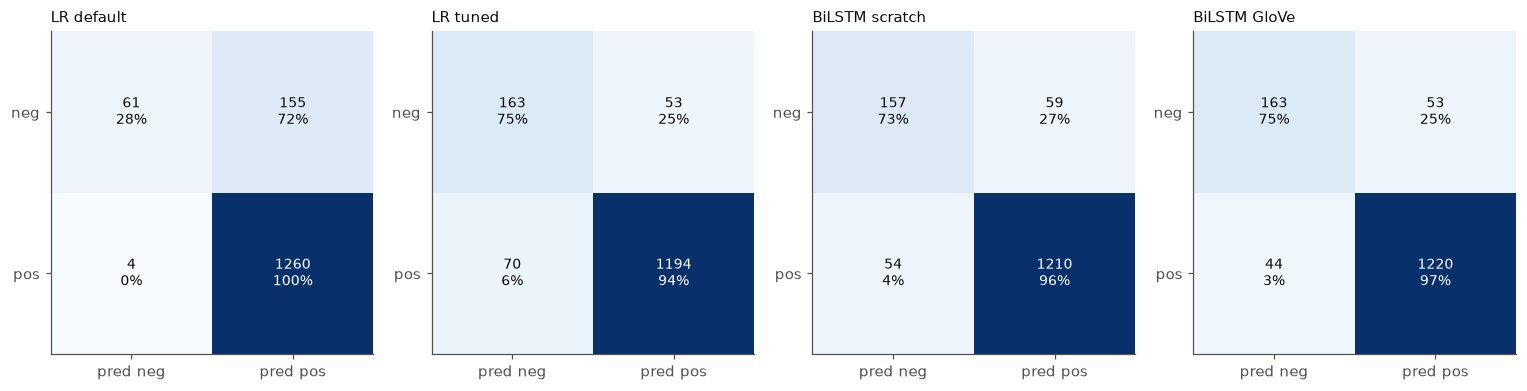

In [14]:
order = ['TF-IDF + LR (default, Part 1)', 'TF-IDF + LR (tuned)', 'BiLSTM-attn A: scratch (3-seed ensemble)', 'BiLSTM-attn B: GloVe (3-seed ensemble)']
short = ['LR default', 'LR tuned', 'BiLSTM scratch', 'BiLSTM GloVe']
cols = [GRAY, AQUA, ORANGE, BLUE]
c2 = comp.set_index('model').loc[order]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (k, title) in zip(axes, [('accuracy', 'Accuracy'), ('macro_f1', 'Macro-F1'), ('recall_neg', 'Negative-class recall')]):
    vals = c2[k].astype(float).values
    bars = ax.barh(short[::-1], vals[::-1], color=cols[::-1], height=0.6)
    for b, v in zip(bars, vals[::-1]):
        ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f'{v:.3f}', va='center', color=INK, fontsize=9)
    ax.set_xlim(max(0, vals.min() - 0.15) if k != 'recall_neg' else 0, 1.02)
    ax.set_title(title + ' (validation)', loc='left', color=INK, fontsize=10); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, name, key in zip(axes, short, ['LR (default)', 'LR (tuned)', 'scratch ensemble', 'glove ensemble']):
    cm = confusion_matrix(y[va_idx], (P[key] >= 0.5).astype(int))
    ax.imshow(cm, cmap='Blues', vmin=0); ax.grid(False)
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, f'{v}\n{v / cm[r].sum():.0%}', ha='center', va='center', color='white' if v > cm.max() / 2 else INK, fontsize=9)
    ax.set_xticks([0, 1], ['pred neg', 'pred pos']); ax.set_yticks([0, 1], ['neg', 'pos'])
    ax.set_title(name, loc='left', color=INK, fontsize=10)
plt.tight_layout(); plt.show()

<!-- COMPARISON_DISCUSSION -->

## 7. Error analysis: where the BiLSTM and the default LR disagree

Attention weights α show which tokens the BiLSTM relied on. The top-5 attended tokens are listed for each review.

In [15]:
best_variant = max(BEST, key=lambda v: comp.set_index('model').loc[
    f"BiLSTM-attn {'A: scratch' if v == 'scratch' else 'B: GloVe'} (3-seed ensemble)", 'macro_f1'])
cfg_b = BEST[best_variant]
m_att, voc_att, *_ = train_model(best_variant, cfg_b, X_text[tr_idx], y[tr_idx], X_text[va_idx], y[va_idx], seed=SEED)
inv = {i: w for w, i in voc_att.items()}

def top_attention(text, k=5):
    toks = tokenize(text)[:MAX_LEN] or ['<unk>']
    ids = [voc_att.get(t, 1) for t in toks]
    m_att.eval()
    with torch.no_grad():
        logits, a = m_att(torch.tensor([ids]), torch.tensor([len(ids)]), return_attn=True)
    a = a[0].numpy()
    return ', '.join(f'{toks[i]}({a[i]:.2f})' for i in np.argsort(-a)[:k])

pb = P[f'{best_variant} ensemble']
ev = pd.DataFrame({'review': X_text[va_idx], 'actual': y[va_idx], 'LR_default_p': p_lr0.round(3), 'BiLSTM_p': pb.round(3)})
ev['LR_ok'] = (p_lr0 >= 0.5) == ev.actual
ev['BiLSTM_ok'] = (pb >= 0.5) == ev.actual
print(pd.crosstab(ev.LR_ok, ev.BiLSTM_ok, rownames=['LR correct'], colnames=['BiLSTM correct']))
print(f'\nBiLSTM ({best_variant}) right, LR wrong:')
a = ev[ev.BiLSTM_ok & ~ev.LR_ok].sort_values('BiLSTM_p').head(6).copy()
a['top attention'] = a.review.map(top_attention)
display(a.drop(columns=['LR_ok', 'BiLSTM_ok']))

BiLSTM correct  False  True 
LR correct                  
False              57    102
True               40   1281

BiLSTM (glove) right, LR wrong:


,review,actual,LR_default_p,BiLSTM_p,top attention
13,"The bra is advertised as 100% cotton, there's only 33% cotton in it, it is not soft whatsoever, you can fe...",0,0.628,0.008,"useless(0.35), mad(0.21), misleading(0.13), completely(0.10), wrong(0.08)"
592,"I wish there was a rating of ""0"". This was very flimsy and the armband is just slightly larger than the s...",0,0.564,0.018,"flimsy(0.64), tore(0.14), very(0.09), completely(0.04), slightly(0.02)"
811,I thought the price of the glasses was too good to turn down so i decided to go through with the purchase....,0,0.503,0.022,"poorly(0.52), cheap(0.30), broke(0.04), very(0.02), throughout(0.01)"
818,"IT IS A HORRIBLE ITEM. IF I COULD HAVE GIVEN THIS HAIRAGAMI A NO STAR RATING, I WOULD HAVE, AND TO THINK ...",0,0.537,0.023,"horrible(0.27), disappointed(0.23), totally(0.15), nightmare(0.13), totally(0.07)"
181,I bought this shirt last yr for my husband. It lasted about 6 months. Much pilling (those horrid dots all ...,0,0.585,0.036,"seams(0.57), fabric(0.08), washings(0.07), coming(0.06), attire(0.04)"
934,"I bought this as a surprise for my wife. When we opened it, I thought that 1) we were shipped a pillowcas...",0,0.563,0.037,"waste(0.18), unfinished(0.16), complete(0.12), picture(0.08), piece(0.07)"


In [16]:
print('BiLSTM wrong (most confident mistakes):')
b = ev[~ev.BiLSTM_ok].assign(conf=lambda d: (d.BiLSTM_p - 0.5).abs()).sort_values('conf', ascending=False).head(6).copy()
b['top attention'] = b.review.map(top_attention)
display(b.drop(columns=['LR_ok', 'BiLSTM_ok', 'conf']))

BiLSTM wrong (most confident mistakes):


,review,actual,LR_default_p,BiLSTM_p,top attention
1148,Shipping was quick. The shoes are comfortable and stay clean longer. When soiled they clean up well. So...,0,0.962,0.998,"pleased(0.50), comfortable(0.29), good(0.03), well(0.02), welcome(0.02)"
1353,Ibought these socks for the purported thermal heating qualities. I was still cold. Just a regular average ...,0,0.926,0.997,"great(0.48), easy(0.36), cold(0.06), so(0.04), just(0.02)"
736,"The 2(x)ist has reasonable support and comfort but most thongs do, so that's nothing special. What's not r...",0,0.914,0.996,"reasonable(0.24), elegant(0.20), dull(0.14), plenty(0.10), best(0.09)"
576,super low price advertised on 'select sizes and colors'.\n\noh and u have to add to your cart before you k...,0,0.942,0.987,"super(0.70), colors(0.18), oh(0.07), and(0.01), low(0.01)"
1065,"I have Goddess bras, and it seems that each style has it's own sizing. The love at first sight bra fits w...",0,0.868,0.986,"wonderfully(0.41), goddess(0.18), own(0.17), sizing(0.09), love(0.08)"
308,I got this bra thinking it would be great for rigorous sports and my 38DDD chest. Think again. Go for th...,0,0.889,0.985,"perfect(0.87), amazed(0.09), is(0.01), bounce(0.01), great(0.01)"


## 8. Test predictions (`test.json`)

The better variant (by ensemble macro-F1 on validation) is refitted on **all 7,401 training reviews**, for the median best epoch of its 3 seed runs, once per seed. The test probabilities are averaged over the 3 seeds and thresholded at 0.5. `test.json` has no labels, so the class distribution is shown instead of an accuracy.

variant glove, config {'lr': 0.001, 'hidden': 256, 'dropout': 0.6, 'class_weight': False}, best epochs per seed [10, 5, 5] -> refit for 5 epochs


  refit seed 42: 63s


  refit seed 43: 63s


  refit seed 44: 63s
saved ~/Desktop/IE4483 Project/sentiment_project/results/submission_bilstm.csv  (1851, 2)
predicted positive rate 92.7% (train: 85.4%); single seeds agree with the ensemble on 98.3% of reviews


agreement with Part 1 LR test predictions: 96.1% (LR predicts 94.4% positive)


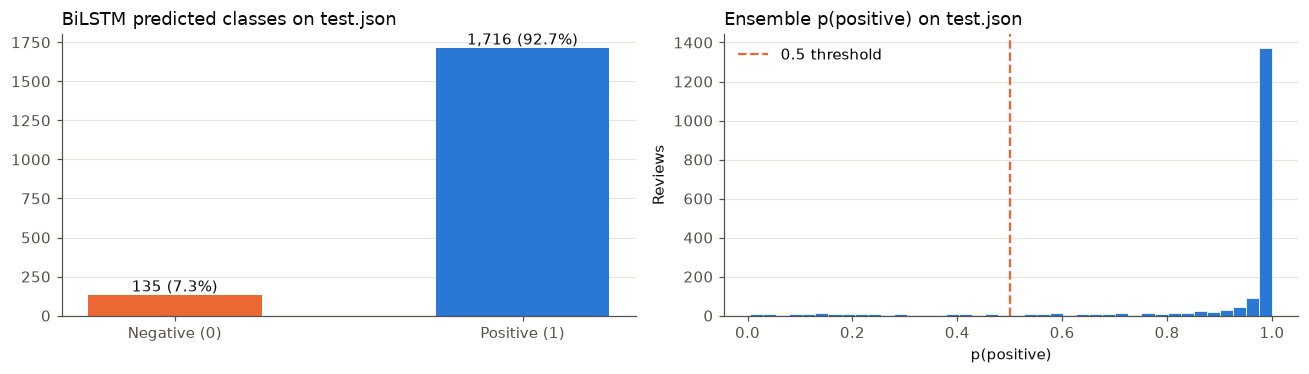

,reviews,predictions,p_positive
0,I bought 2 sleepers. sleeper had holes in the arm pit area and the other sleeper had a whole where the ne...,0,0.046
1,"I dare say these are just about the sexiest things I've ever worn. Oh I've had and have G-strings, have so...",1,0.991
2,"everything about the transaction (price, delivery time, quality of item) was great. I wouldn't hesitate t...",1,0.984
3,"Not bad for just a shirt. Very durable, and matched my teams colors perfectly. Its just a shirt, but it ...",1,0.995
4,"These are truly wrinkle free and longer than the average womans botton down, which I love!! Overall, the...",1,0.999
5,I love naughty monkey! I'm so happy with their shoes! They don't hurt my feet,1,0.999
6,I fell in love with this boot when I first saw it. It was on another store's website for 159.95. I found t...,1,0.969
7,"These shades are a great buy. Fast shipping, great price, and good quality",1,1.000
8,"There was no picture of this selection, so I guessed it was a ""ringer"" type t-shirt. Instead it was a whi...",0,0.294
9,This leather briefcase was exactly what I was looking for. The leather is smooth and supple and holds up ...,1,0.999


In [17]:
cfg_b = BEST[best_variant]
eps = [RUNS[(best_variant, json.dumps(cfg_b, sort_keys=True), s)]['best_epoch'] for s in SEEDS]
final_epochs = int(np.median(eps))
print(f'variant {best_variant}, config {cfg_b}, best epochs per seed {eps} -> refit for {final_epochs} epochs')

test_probs = []
for seed in SEEDS:
    key = ('final', best_variant, json.dumps(cfg_b, sort_keys=True), seed, final_epochs)
    if key not in RUNS:
        model, vocab, *_ , secs = train_model(best_variant, cfg_b, X_text, y, seed=seed, epochs=final_epochs)
        RUNS[key] = {'p_test': predict_proba(model, encode(test_df['reviews'].values, vocab)), 'secs': secs}
        pickle.dump(RUNS, open(CACHE, 'wb'))
        print(f'  refit seed {seed}: {secs:.0f}s')
    test_probs.append(RUNS[key]['p_test'])
p_test = np.mean(test_probs, 0)
pred_test = (p_test >= 0.5).astype(int)
agree = np.mean([(p >= 0.5).astype(int) == pred_test for p in test_probs])

sub = pd.DataFrame({'reviews': test_df['reviews'].values, 'predictions': pred_test})
sub.to_csv(RESULTS / 'submission_bilstm.csv', index=False)
print(f'saved {RESULTS / "submission_bilstm.csv"}  {sub.shape}')
print(f'predicted positive rate {pred_test.mean():.1%} (train: {y.mean():.1%}); single seeds agree with the ensemble on {agree:.1%} of reviews')

lr_test = LogisticRegression(max_iter=1000, random_state=SEED)
v_all = TfidfVectorizer().fit(X_text); lr_test.fit(v_all.transform(X_text), y)
pred_lr_test = lr_test.predict(v_all.transform(test_df['reviews']))
print(f'agreement with Part 1 LR test predictions: {np.mean(pred_lr_test == pred_test):.1%} '
      f'(LR predicts {pred_lr_test.mean():.1%} positive)')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
tc = np.bincount(pred_test, minlength=2)
bars = axes[0].bar(['Negative (0)', 'Positive (1)'], tc, color=[ORANGE, BLUE], width=0.5)
for bb, v in zip(bars, tc):
    axes[0].text(bb.get_x() + bb.get_width() / 2, v + 20, f'{v:,} ({v / tc.sum():.1%})', ha='center', color=INK)
axes[0].set_title('BiLSTM predicted classes on test.json', loc='left', color=INK); axes[0].grid(axis='x', visible=False)
axes[1].hist(p_test, bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].axvline(0.5, color=ORANGE, linestyle='--', linewidth=1.5, label='0.5 threshold')
axes[1].set_title('Ensemble p(positive) on test.json', loc='left', color=INK)
axes[1].set_xlabel('p(positive)'); axes[1].set_ylabel('Reviews'); axes[1].legend(frameon=False); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
sub.assign(p_positive=p_test.round(3)).head(10)

<!-- SUMMARY -->